Freeform GPT Features — EDA + XGBoost

1. Load & inspect freeform feature CSV
2. Sanity checks vs RDKit ground truth (side-by-side grid)
3. Cross-correlation heatmap: RDKit vs freeform GPT
4. Build feature matrix
5. XGBoost — exact same pipeline as `build_train.py`

**Only change the config cell when switching models.**

In [1]:
from IPython.display import display
import warnings, random
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve,
    f1_score, precision_score, recall_score, accuracy_score, matthews_corrcoef
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import xgboost as xgb

def find_data_dir():
    here = Path().resolve()
    for candidate in [here / "data", here.parent / "data"]:
        if (candidate / "prestwick_library_screened.tsv.gz").exists():
            return candidate
    raise FileNotFoundError(f"Cannot find data/ from {here}")

DATA_DIR   = find_data_dir()
RDKIT_PATH = DATA_DIR / "maier_chemdesc_representation.tsv"
PAIRS_FILE = DATA_DIR / "results" / "mole_plus_gpt41mini" / "compound_strain_pairs_with_features_mole_plus_gpt.csv"

# ── Change these two lines to switch models ────────────────────────────────────
FREEFORM_CSV = DATA_DIR / "gpt_generation_without_guidance" / "gpt_features4o_gpt-4o_freeform.csv"
MODEL_TAG    = "gpt-4o-freeform"

OUT_DIR = DATA_DIR / "feature_matrix_gpt" / "freeform" / MODEL_TAG
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Freeform CSV : {FREEFORM_CSV}")
print(f"Output dir   : {OUT_DIR}")

Freeform CSV : D:\Hiwi\GPT+Mole\GPT+Mole\data\gpt_generation_without_guidance\gpt_features4o_gpt-4o_freeform.csv
Output dir   : D:\Hiwi\GPT+Mole\GPT+Mole\data\feature_matrix_gpt\freeform\gpt-4o-freeform


## 1. Load & Inspect

In [2]:
raw = pd.read_csv(FREEFORM_CSV)
META_COLS    = {"prestwick_ID", "smiles_resolution", "input"}
feature_cols = [c for c in raw.columns if c not in META_COLS]

print(f"Shape        : {raw.shape}")
print(f"Feature cols : {feature_cols}")
raw.head(3)

Shape        : (1197, 269)
Feature cols : ['num_atoms', 'num_heavy_atoms', 'num_hydrogen_atoms', 'num_nitrogen_atoms', 'num_oxygen_atoms', 'num_carbon_atoms', 'num_aromatic_rings', 'num_heteroatoms', 'num_h_bond_donors', 'num_h_bond_acceptors', 'molecular_weight', 'topological_polar_surface_area', 'num_rotatable_bonds', 'num_aliphatic_rings', 'num_aromatic_heterocycles', 'num_aliphatic_heterocycles', 'num_aromatic_carbocycles', 'num_aliphatic_carbocycles', 'num_saturated_rings', 'num_unsaturated_rings', 'num_amide_bonds', 'num_ester_bonds', 'num_ether_bonds', 'num_thioether_bonds', 'num_halogen_atoms', 'num_sulfur_atoms', 'num_phosphorus_atoms', 'num_quaternary_carbons', 'num_tertiary_carbons', 'num_secondary_carbons', 'num_primary_carbons', 'num_tertiary_nitrogens', 'num_secondary_nitrogens', 'num_primary_nitrogens', 'num_quaternary_nitrogens', 'num_tertiary_oxygens', 'num_secondary_oxygens', 'num_primary_oxygens', 'logp', 'molar_refractivity', 'num_hydrophilic_groups', 'num_hydrophob

,num_atoms,num_heavy_atoms,num_hydrogen_atoms,num_nitrogen_atoms,num_oxygen_atoms,num_carbon_atoms,num_aromatic_rings,num_heteroatoms,num_h_bond_donors,num_h_bond_acceptors,...,num_chiral_centers_trigonal_bipyramidal_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_square_pyramidal_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_trigonal_prismatic_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_square_antiprismatic_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_pentagonal_bipyramidal_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_hexagonal_bipyramidal_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_cubic_rotational_conformational_rotational_conformational_rotational_tautomers,input,prestwick_ID,smiles_resolution
0,10.0,9.0,1.0,5.0,1.0,3.0,1.0,6.0,2.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"{'query_smiles': 'Nc1nc2n[nH]nc2c(=O)[nH]1', '...",Prestw-1,fast
1,17.0,12.0,5.0,3.0,2.0,7.0,1.0,5.0,3.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,{'query_smiles': 'NC(N)=NS(=O)(=O)c1ccc(N)cc1'...,Prestw-10,fast
2,28.0,21.0,7.0,2.0,3.0,15.0,3.0,5.0,1.0,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,{'query_smiles': 'COC(=O)Nc1nc2ccc(C(=O)c3cccs...,Prestw-100,fast


In [3]:
print(pd.DataFrame({"dtype": raw[feature_cols].dtypes,
                     "nulls": raw[feature_cols].isnull().sum()}))
raw[feature_cols].describe().round(3)

                                                      dtype  nulls
num_atoms                                           float64      8
num_heavy_atoms                                     float64      8
num_hydrogen_atoms                                  float64      8
num_nitrogen_atoms                                  float64      8
num_oxygen_atoms                                    float64      8
...                                                     ...    ...
num_chiral_centers_trigonal_prismatic_rotationa...  float64    102
num_chiral_centers_square_antiprismatic_rotatio...  float64    102
num_chiral_centers_pentagonal_bipyramidal_rotat...  float64    102
num_chiral_centers_hexagonal_bipyramidal_rotati...  float64    102
num_chiral_centers_cubic_rotational_conformatio...  float64    102

[266 rows x 2 columns]


,num_atoms,num_heavy_atoms,num_hydrogen_atoms,num_nitrogen_atoms,num_oxygen_atoms,num_carbon_atoms,num_aromatic_rings,num_heteroatoms,num_h_bond_donors,num_h_bond_acceptors,...,num_chiral_centers_trigonal_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_square_planar_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_octahedral_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_trigonal_bipyramidal_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_square_pyramidal_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_trigonal_prismatic_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_square_antiprismatic_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_pentagonal_bipyramidal_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_hexagonal_bipyramidal_rotational_conformational_rotational_conformational_rotational_tautomers,num_chiral_centers_cubic_rotational_conformational_rotational_conformational_rotational_tautomers
count,1189.000,1189.000,1189.000,1189.000,1189.000,1189.000,1189.000,1189.000,1189.000,1189.000,...,1095.0,1095.0,1095.0,1095.0,1095.0,1095.0,1095.0,1095.0,1095.0,1095.0
mean,30.224,22.413,10.611,1.939,2.898,18.215,1.463,5.008,1.377,4.089,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
std,15.033,10.388,8.535,1.593,2.622,8.976,0.975,3.288,1.540,2.678,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
min,7.000,6.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,21.000,15.000,6.000,1.000,1.000,11.000,1.000,3.000,0.000,2.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50%,27.000,21.000,8.000,2.000,2.000,17.000,1.000,4.000,1.000,3.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
75%,38.000,28.000,13.000,3.000,4.000,23.000,2.000,6.000,2.000,5.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,122.000,85.000,50.000,15.000,18.000,63.000,8.000,30.000,14.000,20.000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0




In [4]:
n, ncols = len(feature_cols), 4
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3))
axes = axes.flatten()
for i, col in enumerate(feature_cols):
    axes[i].hist(raw[col].dropna(), bins=40, color="#185FA5", alpha=0.75, edgecolor="none")
    axes[i].set_title(col, fontsize=8)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
fig.suptitle(f"Feature Distributions — {MODEL_TAG}", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Sanity Checks vs RDKit (Side-by-Side)

In [5]:
rdkit = pd.read_csv(RDKIT_PATH, sep="\t")

# GPT feature name -> closest RDKit column
SANITY_MAP = {
    "molecular_weight":               "MolWt",
    "num_hydrogen_bond_donors":       "NumHDonors",
    "num_hydrogen_bond_acceptors":    "NumHAcceptors",
    "num_aromatic_rings":             "NumAromaticRings",
    "num_rings":                      "NumRings",
    "topological_polar_surface_area": "TPSA",
    "fraction_csp3":                  "FractionCSP3",
    "num_rotatable_bonds":            "NumRotatableBonds",
}

valid_pairs = [(g, r) for g, r in SANITY_MAP.items()
               if g in raw.columns and r in rdkit.columns]
print(f"Sanity check pairs: {len(valid_pairs)}")
for g, r in valid_pairs:
    print(f"  {g:42s} -> {r}")

Sanity check pairs: 4
  molecular_weight                           -> MolWt
  num_aromatic_rings                         -> NumAromaticRings
  topological_polar_surface_area             -> TPSA
  num_rotatable_bonds                        -> NumRotatableBonds


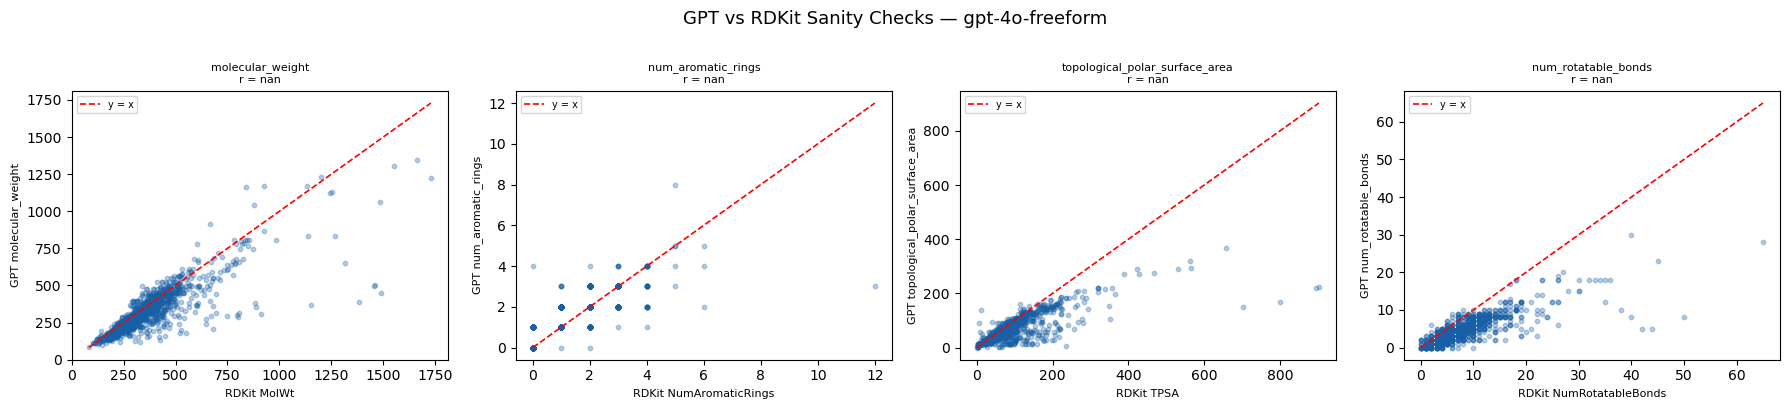

5 MOST SIMILAR (GPT ≈ RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-1060,293.322,293.32,-0.0
1,Prestw-1202,153.137,153.14,0.0
2,Prestw-1207,180.159,180.16,0.0
3,Prestw-1213,136.114,136.11,-0.0
4,Prestw-1256,194.194,194.19,-0.0



5 MOST OVERESTIMATED (GPT >> RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-854,837.058,1160.56,323.50
1,Prestw-1036,666.910,914.17,247.26
2,Prestw-410,924.091,1170.56,246.47
3,Prestw-12,603.750,776.96,173.21
4,Prestw-1157,877.045,1045.23,168.18



5 MOST UNDERESTIMATED (GPT << RDKit):


,prestwick_ID,rdkit_MolWt,gpt_MolWt,diff
0,Prestw-160,1488.807,447.57,-1041.24
1,Prestw-506,1385.461,389.44,-996.02
2,Prestw-321,1457.397,493.44,-963.96
3,Prestw-159,1461.429,503.44,-957.99
4,Prestw-1040,1151.421,368.32,-783.10


In [6]:
merged = raw[["prestwick_ID"] + [g for g, _ in valid_pairs]].merge(
    rdkit[["prestwick_ID"] + [r for _, r in valid_pairs]], on="prestwick_ID", how="inner"
)

n_pairs = len(valid_pairs)
ncols   = min(4, n_pairs)
nrows   = (n_pairs + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.5, nrows * 4))
axes = np.array(axes).flatten()

sanity_results = []
for i, (gpt_col, rdkit_col) in enumerate(valid_pairs):
    ax   = axes[i]
    x, y = merged[rdkit_col], merged[gpt_col]
    r, p  = spearmanr(x, y)
    sanity_results.append({"gpt": gpt_col, "rdkit": rdkit_col,
                            "spearman_r": round(r, 4), "p": round(p, 6)})
    ax.scatter(x, y, alpha=0.3, s=10, color="#185FA5", rasterized=True)
    mn, mx = min(x.min(), y.min()), max(x.max(), y.max())
    ax.plot([mn, mx], [mn, mx], "r--", lw=1.2, label="y = x")
    ax.set_xlabel(f"RDKit {rdkit_col}", fontsize=8)
    ax.set_ylabel(f"GPT {gpt_col}", fontsize=8)
    ax.set_title(f"{gpt_col}\nr = {r:.3f}", fontsize=8)
    ax.legend(fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(f"GPT vs RDKit Sanity Checks — {MODEL_TAG}", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / "sanity_checks.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Molecular weight deep-dive table ──────────────────────────────────────────
mw_gpt_col   = "molecular_weight"
mw_rdkit_col = "MolWt"

if mw_gpt_col in merged.columns and mw_rdkit_col in merged.columns:
    mw = merged[["prestwick_ID", mw_rdkit_col, mw_gpt_col]].copy()
    mw = mw.rename(columns={mw_rdkit_col: "rdkit_MolWt", mw_gpt_col: "gpt_MolWt"})
    mw["diff"]     = (mw["gpt_MolWt"] - mw["rdkit_MolWt"]).round(2)
    mw["abs_diff"] = mw["diff"].abs()

    closest   = mw.nsmallest(5, "abs_diff").reset_index(drop=True)
    overest   = mw.nlargest(5,  "diff").reset_index(drop=True)
    underest  = mw.nsmallest(5, "diff").reset_index(drop=True)

    print("5 MOST SIMILAR (GPT ≈ RDKit):")
    display(closest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

    print("\n5 MOST OVERESTIMATED (GPT >> RDKit):")
    display(overest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

    print("\n5 MOST UNDERESTIMATED (GPT << RDKit):")
    display(underest[["prestwick_ID", "rdkit_MolWt", "gpt_MolWt", "diff"]])

## 3. Cross-Correlation: RDKit vs Freeform GPT

RDKit: 96 features  |  GPT freeform: 68 features


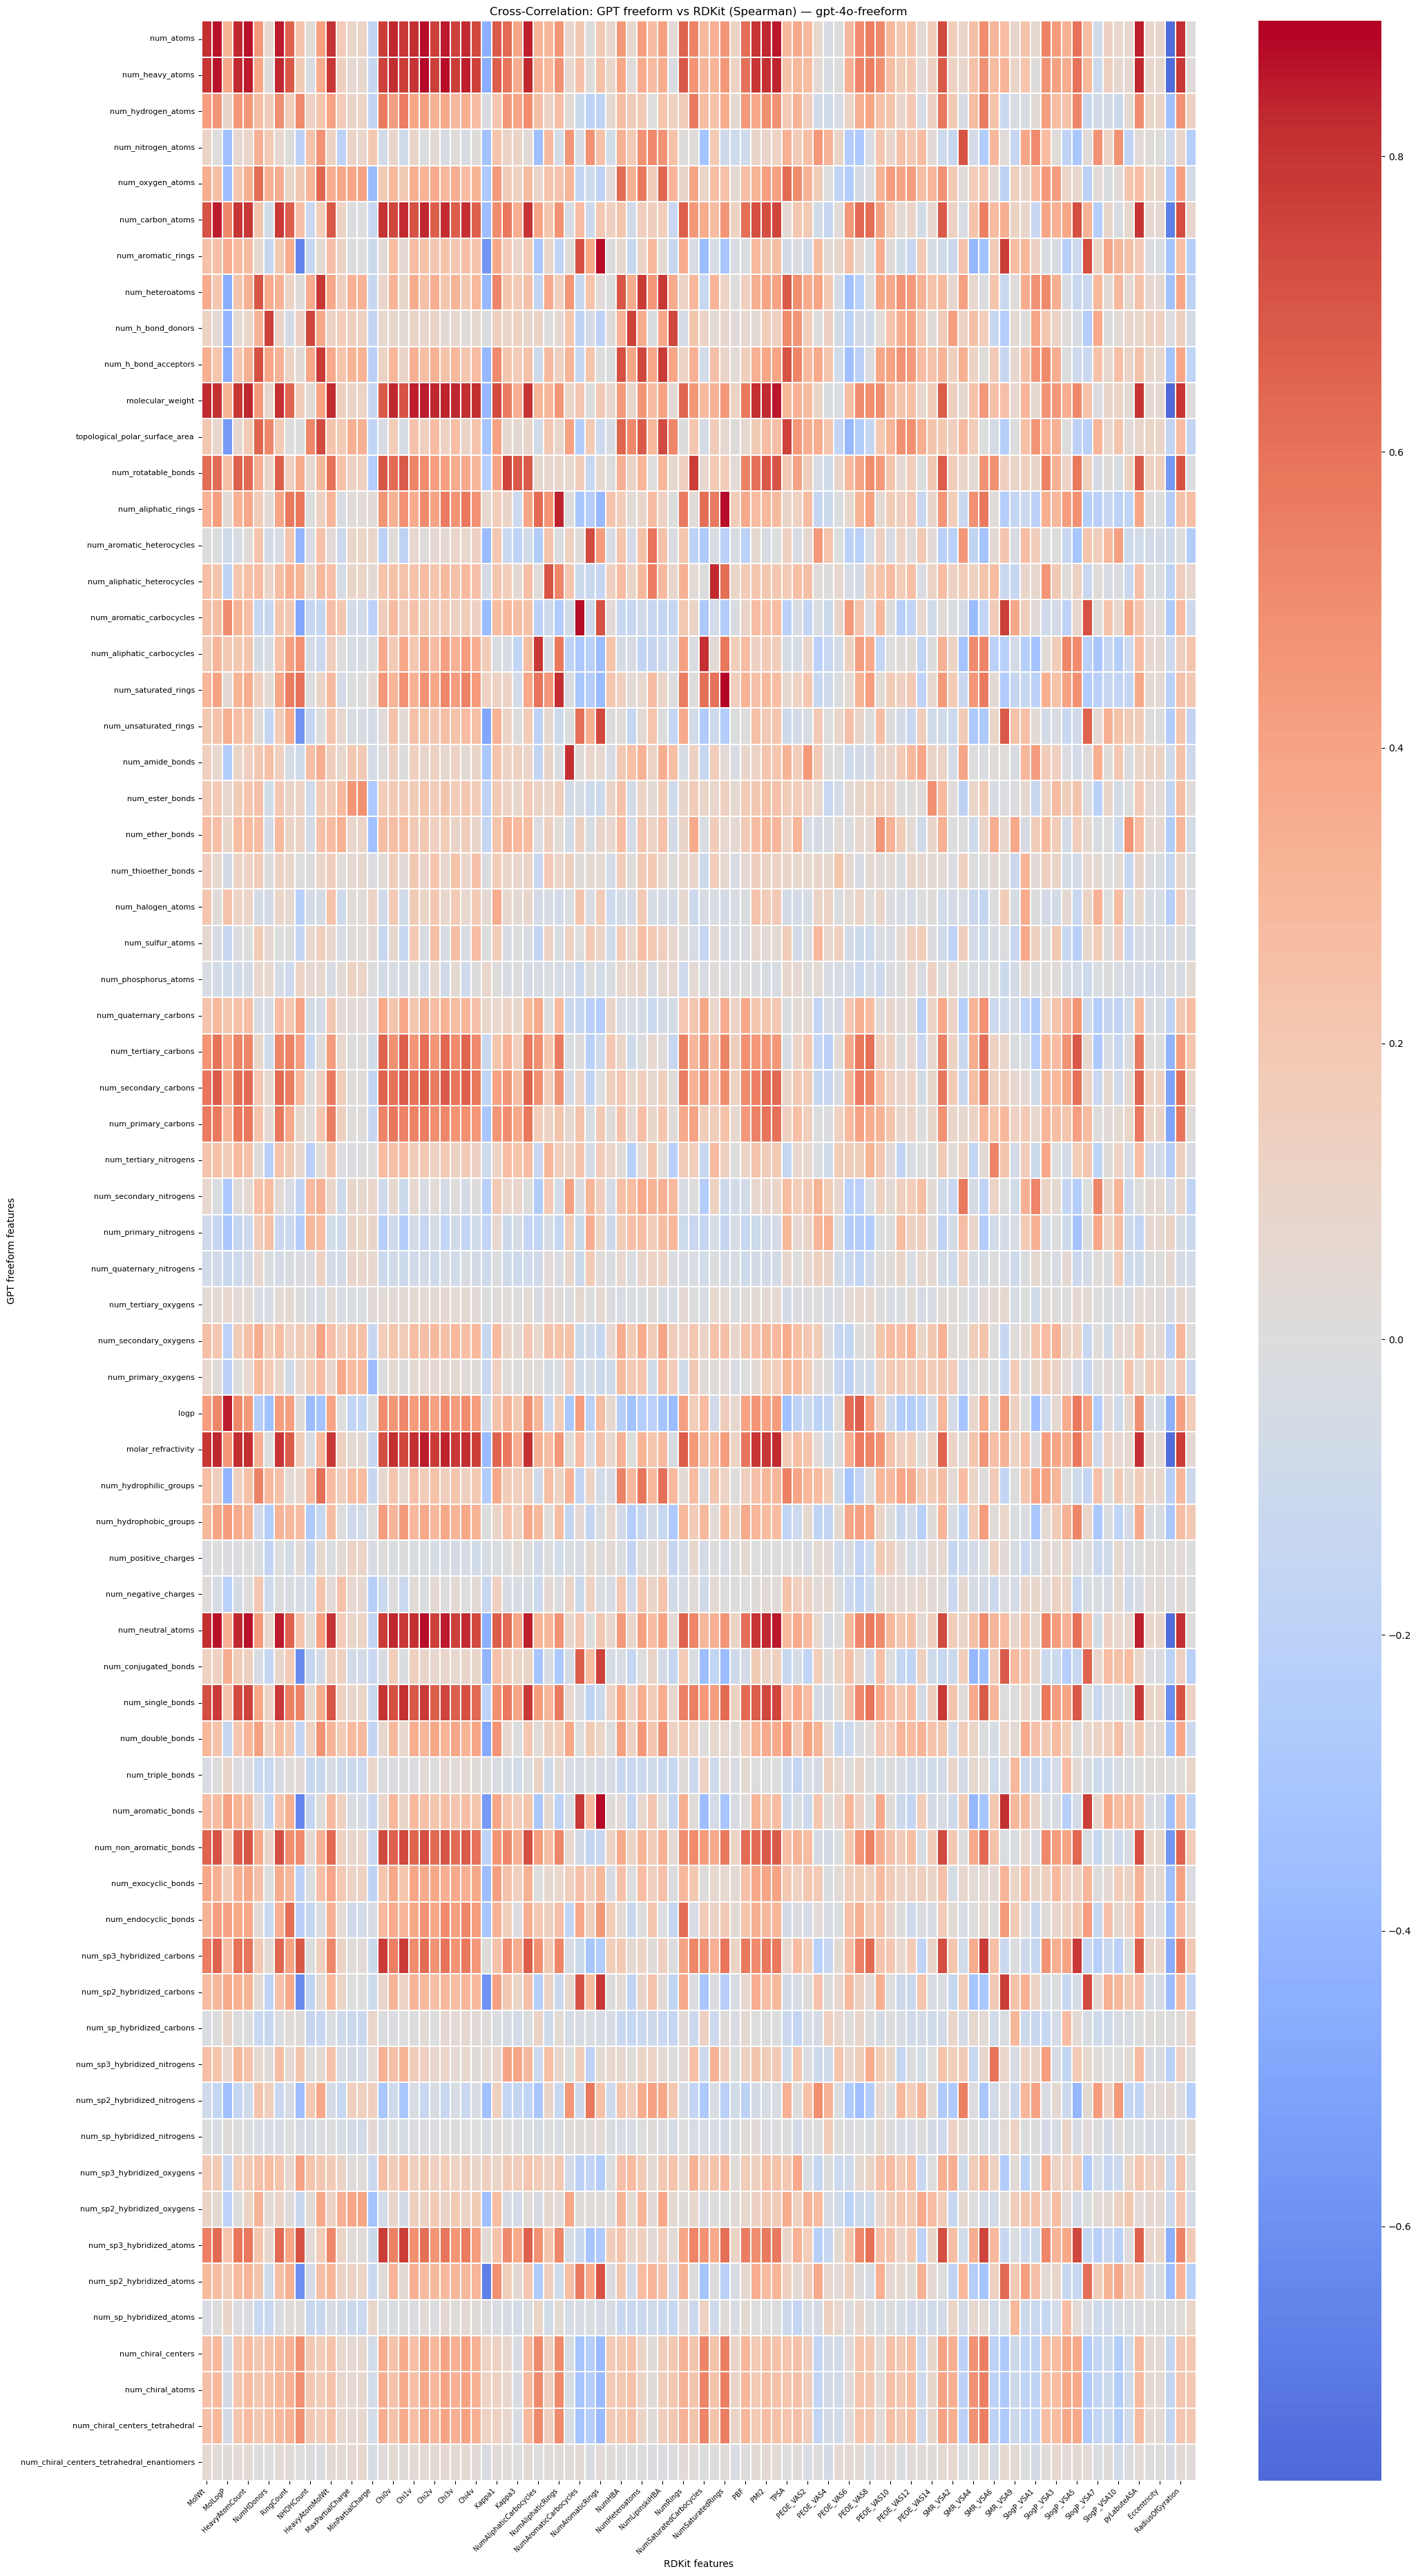

In [7]:
rdkit_al = (rdkit.set_index("prestwick_ID")
                .apply(pd.to_numeric, errors="coerce").fillna(0))
rdkit_al = rdkit_al.loc[:, rdkit_al.std() > 1e-6]

gpt_al = (raw.set_index("prestwick_ID")[feature_cols]
             .apply(pd.to_numeric, errors="coerce").fillna(0))
gpt_al = gpt_al.loc[:, gpt_al.std() > 1e-6]

common   = rdkit_al.index.intersection(gpt_al.index)
rdkit_al = rdkit_al.loc[common].sort_index()
gpt_al   = gpt_al.loc[common].sort_index()

rdkit_al.columns = ["rdkit__" + c for c in rdkit_al.columns]
gpt_al.columns   = ["gpt__"   + c for c in gpt_al.columns]

n_rdkit, n_gpt = rdkit_al.shape[1], gpt_al.shape[1]
print(f"RDKit: {n_rdkit} features  |  GPT freeform: {n_gpt} features")

# Compute only the GPT × RDKit cross-correlation block
combined_all = pd.concat([rdkit_al, gpt_al], axis=1)
full_corr    = combined_all.corr(method="spearman")
corr_sp      = full_corr   # keep for novelty cell downstream

rdkit_cols_idx = [c for c in full_corr.columns if c.startswith("rdkit__")]
gpt_cols_idx   = [c for c in full_corr.columns if c.startswith("gpt__")]
cross_block    = full_corr.loc[gpt_cols_idx, rdkit_cols_idx]

# Clean axis labels (remove prefixes)
cross_block.index   = [c.replace("gpt__", "")   for c in cross_block.index]
cross_block.columns = [c.replace("rdkit__", "") for c in cross_block.columns]

fig, ax = plt.subplots(figsize=(max(20, n_rdkit * 0.22), max(4, n_gpt * 0.55)))
sns.heatmap(cross_block, cmap="coolwarm", center=0, annot=(n_gpt <= 30),
            fmt=".2f", linewidths=0.3, rasterized=True, ax=ax)
ax.set_title(f"Cross-Correlation: GPT freeform vs RDKit (Spearman) — {MODEL_TAG}", fontsize=12)
ax.set_xlabel("RDKit features", fontsize=10)
ax.set_ylabel("GPT freeform features", fontsize=10)
plt.xticks(rotation=45, ha="right", fontsize=7)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "cross_corr_gpt_vs_rdkit.png", dpi=150, bbox_inches="tight")
plt.show()

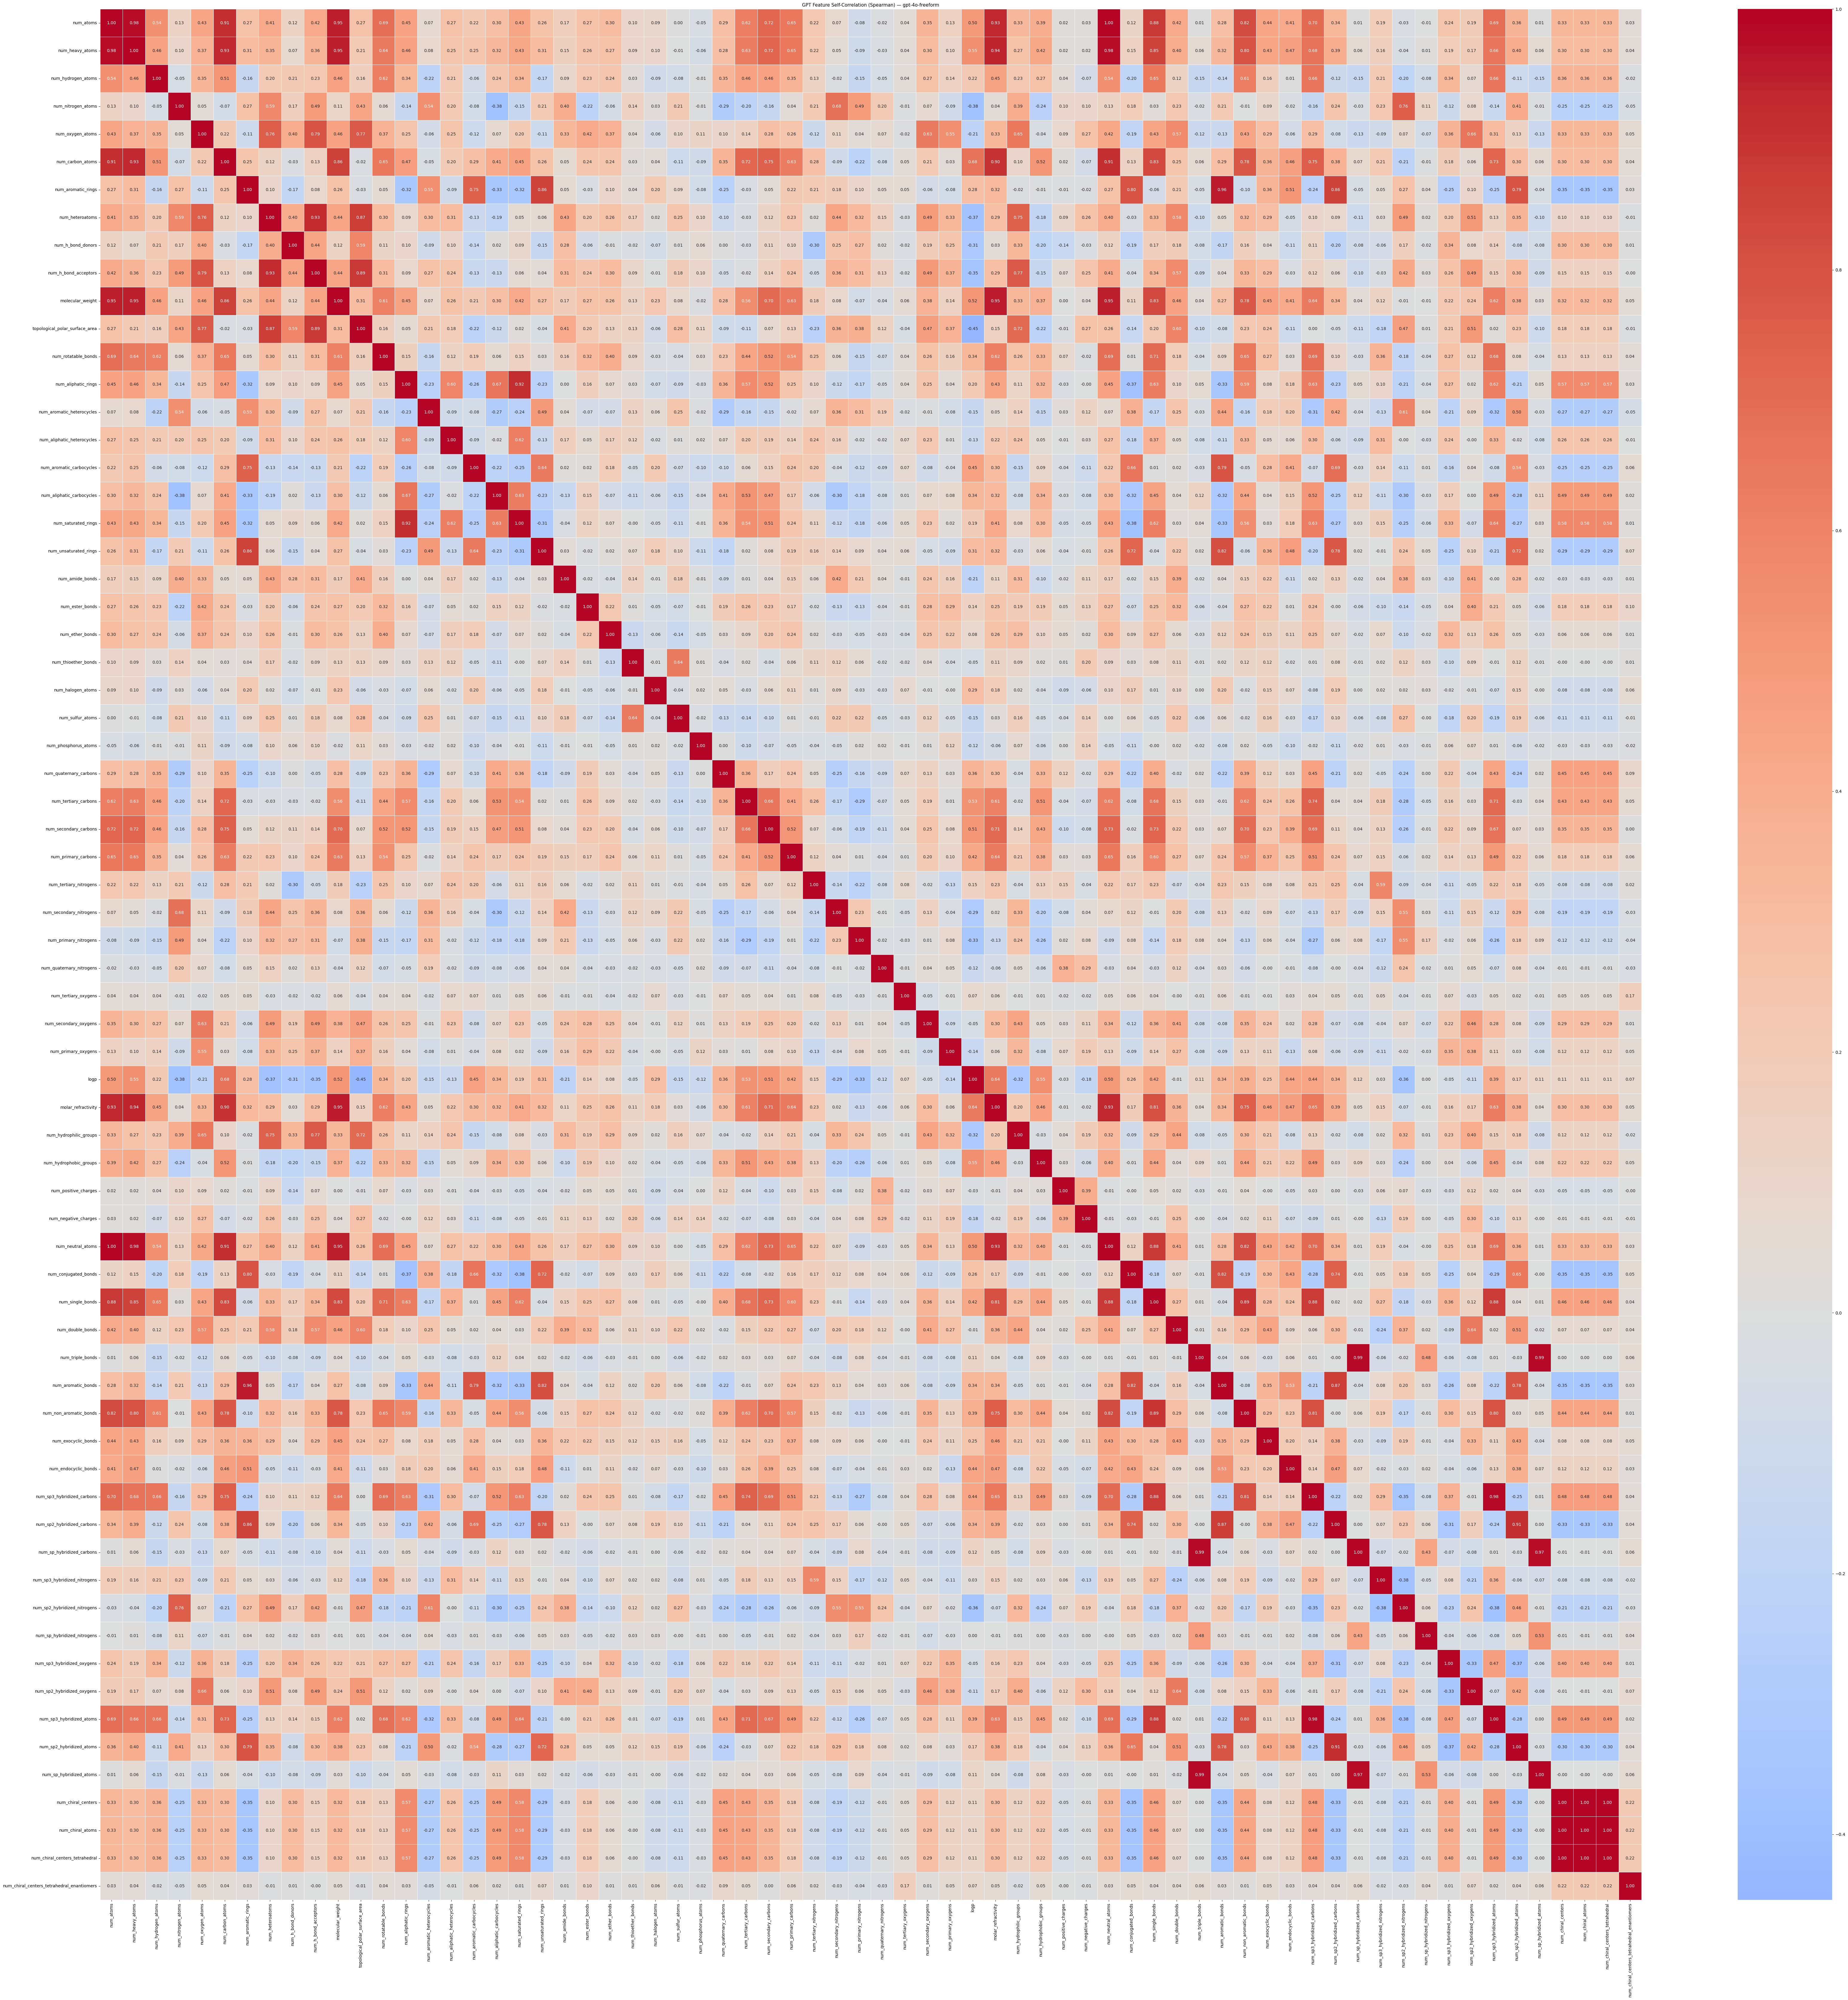

In [8]:
corr_self  = gpt_al.corr(method="spearman")
gpt_labels = [c.replace("gpt__", "") for c in gpt_al.columns]

fig, ax = plt.subplots(figsize=(max(8, n_gpt), max(7, n_gpt - 1)))
sns.heatmap(corr_self, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            xticklabels=gpt_labels, yticklabels=gpt_labels, linewidths=0.4, ax=ax)
ax.set_title(f"GPT Feature Self-Correlation (Spearman) — {MODEL_TAG}", fontsize=11)
plt.tight_layout()
plt.savefig(OUT_DIR / "self_corr.png", dpi=150, bbox_inches="tight")
plt.show()

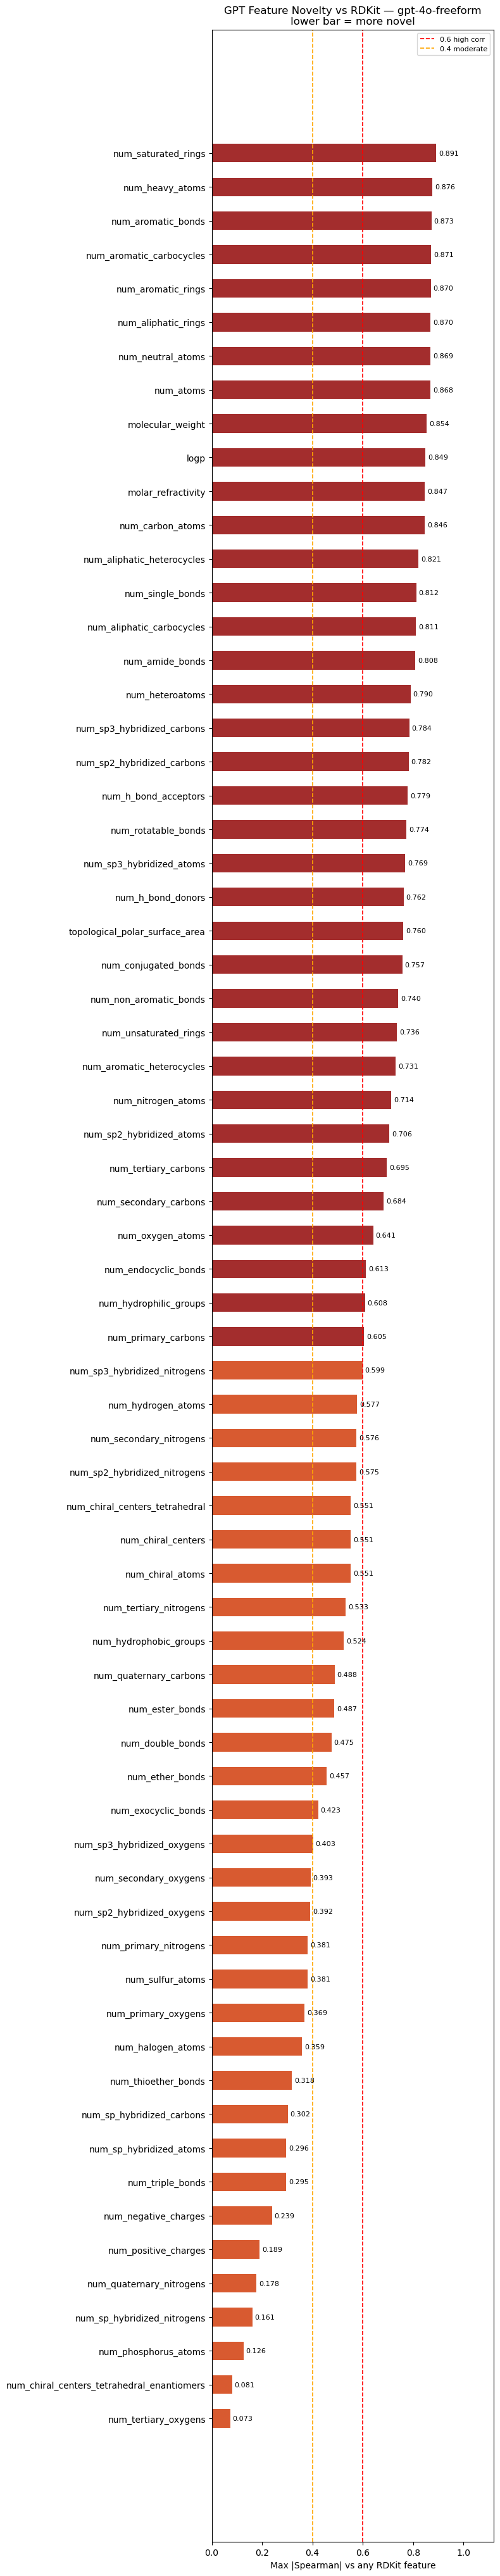

,gpt_feature,max_r_vs_rdkit,closest_rdkit
35,num_tertiary_oxygens,0.072912,SlogP_VSA1
67,num_chiral_centers_tetrahedral_enantiomers,0.080562,SlogP_VSA10
26,num_phosphorus_atoms,0.125709,MaxPartialCharge
58,num_sp_hybridized_nitrogens,0.160763,PEOE_VAS4
34,num_quaternary_nitrogens,0.177796,NumAromaticHeterocycles
...,...,...,...
6,num_aromatic_rings,0.869896,NumAromaticRings
16,num_aromatic_carbocycles,0.871248,NumAromaticCarbocycles
49,num_aromatic_bonds,0.872881,NumAromaticRings
1,num_heavy_atoms,0.875650,Chi2n


In [9]:
rdkit_cols_list = [c for c in corr_sp.columns if c.startswith("rdkit__")]
gpt_cols_list   = [c for c in corr_sp.columns if c.startswith("gpt__")]

novelty = []
for g in gpt_cols_list:
    row = corr_sp.loc[g, rdkit_cols_list].abs()
    novelty.append({"gpt_feature": g.replace("gpt__", ""),
                    "max_r_vs_rdkit": float(row.max()),
                    "closest_rdkit": row.idxmax().replace("rdkit__", "")})

nov_df = pd.DataFrame(novelty).sort_values("max_r_vs_rdkit", ascending=True)

fig, ax = plt.subplots(figsize=(8, max(3, len(nov_df) * 0.6)))
colors  = ["#A32D2D" if r > 0.6 else "#D85A30" for r in nov_df["max_r_vs_rdkit"]]
bars    = ax.barh(nov_df["gpt_feature"], nov_df["max_r_vs_rdkit"], color=colors, height=0.55)
ax.axvline(0.6, color="red",    linestyle="--", lw=1.2, label="0.6 high corr")
ax.axvline(0.4, color="orange", linestyle="--", lw=1.2, label="0.4 moderate")
for bar, val in zip(bars, nov_df["max_r_vs_rdkit"]):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=8)
ax.set_xlabel("Max |Spearman| vs any RDKit feature")
ax.set_title(f"GPT Feature Novelty vs RDKit — {MODEL_TAG}\nlower bar = more novel")
ax.legend(fontsize=8)
ax.set_xlim(0, 1.12)
plt.tight_layout()
plt.savefig(OUT_DIR / "novelty_bar.png", dpi=150, bbox_inches="tight")
plt.show()
nov_df

## 4. Build Feature Matrix

In [10]:
feat_df = raw[["prestwick_ID"] + feature_cols].copy()
for col in feature_cols:
    feat_df[col] = pd.to_numeric(feat_df[col], errors="coerce").fillna(0)

keep    = [c for c in feature_cols if feat_df[c].std() > 1e-6]
dropped = [c for c in feature_cols if c not in keep]
if dropped:
    print(f"Dropped zero-variance: {dropped}")
feat_df = feat_df[["prestwick_ID"] + keep]
print(f"Feature matrix: {feat_df.shape}  ({len(feature_cols)} -> {len(keep)} features)")

Dropped zero-variance: ['num_sp_hybridized_oxygens', 'num_chiral_bonds', 'num_chiral_centers_trigonal', 'num_chiral_centers_square_planar', 'num_chiral_centers_octahedral', 'num_chiral_centers_trigonal_bipyramidal', 'num_chiral_centers_square_pyramidal', 'num_chiral_centers_trigonal_prismatic', 'num_chiral_centers_square_antiprismatic', 'num_chiral_centers_pentagonal_bipyramidal', 'num_chiral_centers_hexagonal_bipyramidal', 'num_chiral_centers_cubic', 'num_chiral_centers_trigonal_enantiomers', 'num_chiral_centers_square_planar_enantiomers', 'num_chiral_centers_octahedral_enantiomers', 'num_chiral_centers_trigonal_bipyramidal_enantiomers', 'num_chiral_centers_square_pyramidal_enantiomers', 'num_chiral_centers_trigonal_prismatic_enantiomers', 'num_chiral_centers_square_antiprismatic_enantiomers', 'num_chiral_centers_pentagonal_bipyramidal_enantiomers', 'num_chiral_centers_hexagonal_bipyramidal_enantiomers', 'num_chiral_centers_cubic_enantiomers', 'num_chiral_centers_tetrahedral_diastereo

In [11]:
pairs = pd.read_csv(PAIRS_FILE, usecols=["prestwick_ID", "bacterium", "label", "split"])
print(f"Pairs: {pairs.shape}  |  label dist: {pairs['label'].value_counts().to_dict()}")

df = pairs.merge(feat_df, on="prestwick_ID", how="inner")
missing = set(pairs["prestwick_ID"]) - set(feat_df["prestwick_ID"])
print(f"After merge: {df.shape}  |  unmatched compounds: {len(missing)}")

Pairs: (47880, 4)  |  label dist: {0: 41338, 1: 6542}
After merge: (47880, 72)  |  unmatched compounds: 0
